# 02 · Exploratory data analysis and hypothesis tests
**Project:** Next-day PM2.5 exceedance alerts for Chennai · CS3006 · pipeline stage **4 EDA & Statistics**

**Question for this stage:** *what does the data look like, and which signals could tell us
today that tomorrow will be over 60 µg/m³?* Every finding ends with what it means for
the features (stage 5) or the model (stage 6).

### Ground rule: EDA looks at the training years only (2021-2023)
EDA is for *forming* hypotheses. If we chose features by looking at 2024-2026, the
validation and test scores would no longer be an honest check, because we would have
tuned to them without noticing. So every plot and test below uses the **training
split only**. The one exception is §9, which shows only the *share* of bad days per
year. That number was already reported in the audit (notebook 01), it does not
influence any feature choice, and it is needed to discuss data drift.

**A note on p-values.** Station-days are not independent: tomorrow looks like today.
Textbook tests assume independent rows, so they *overstate* significance. We therefore
(a) lead with **effect sizes and confidence intervals**, and (b) re-check each key test
with an "effective sample size" (§4).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # run from the notebooks/ folder

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config as C, eda
from src.dataset import build_frame, festival_flags
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
np.random.seed(C.RANDOM_SEED)                   # nothing here is random; set for consistency

def show(fig_path):
    display(Image(str(fig_path)))

def table(d):
    # print a test result dict as a one-row table, p-values in scientific notation
    return pd.Series({k: (f"{v:.2e}" if k.startswith("p_") else v) for k, v in d.items()
                      if k != "table"}).to_frame("value")

## 0 · The modelling table
`src/dataset.py` builds one row per **(station, day D)** with day-D pollution, day-D
weather (Open-Meteo), and the target `y = 1 if PM2.5 on D+1 > 60`.
Rows are assigned to a split by the year of the **target day**: the row for 31 Dec 2023
predicts 1 Jan 2024, so it belongs to validation. Otherwise one day's answer would leak
across the boundary.

In [2]:
df = build_frame()
tr = df[df["split"] == "train"].copy()
print("all rows:", df.shape, "| training rows:", len(tr))
df.groupby("split", sort=False).agg(rows=("y", "size"), labelled=("y", "count"),
                                    exceed_days=("y", "sum"), exceed_rate=("y", "mean"))

all rows: (8576, 37) | training rows: 4376


,rows,labelled,exceed_days,exceed_rate
split,,,,
train,4376,3506,215,0.06132
val,1464,902,76,0.08426
test,1460,1210,157,0.1298
monitor,1276,1211,151,0.1247


In [3]:
tr[["date", "station", "pm25", "pm25_next", "y", "split", "w_temp_mean", "w_rain_mm", "w_wind_v"]].head()

,date,station,pm25,pm25_next,y,split,w_temp_mean,w_rain_mm,w_wind_v
0,2021-01-01,Manali,43.48,40.63,0,train,25.41,0,-2.97
1,2021-01-02,Manali,40.63,35.14,0,train,24.43,17.6,-3.224
2,2021-01-03,Manali,35.14,34.81,0,train,25.14,4.3,-2.98
3,2021-01-04,Manali,34.81,32.75,0,train,25.04,3,-2.526
4,2021-01-05,Manali,32.75,49.15,0,train,24.64,16.6,-1.382


## 1 · The target: centre, spread, shape and imbalance

In [4]:
eda.describe(tr)

,n,mean,median,std,IQR,skew,p95,max
station,,,,,,,,
Manali,1075,27.57,22.91,17.1,19.12,2.52,60.3,205.9
Kodungaiyur,314,28.9,22.77,19.08,23.2,1.57,67.11,128.8
Arumbakkam,1050,30.35,25.54,17.18,19.16,1.75,64.12,168
Perungudi,1068,24.52,17.72,20.08,22.16,2.27,62.88,203.7


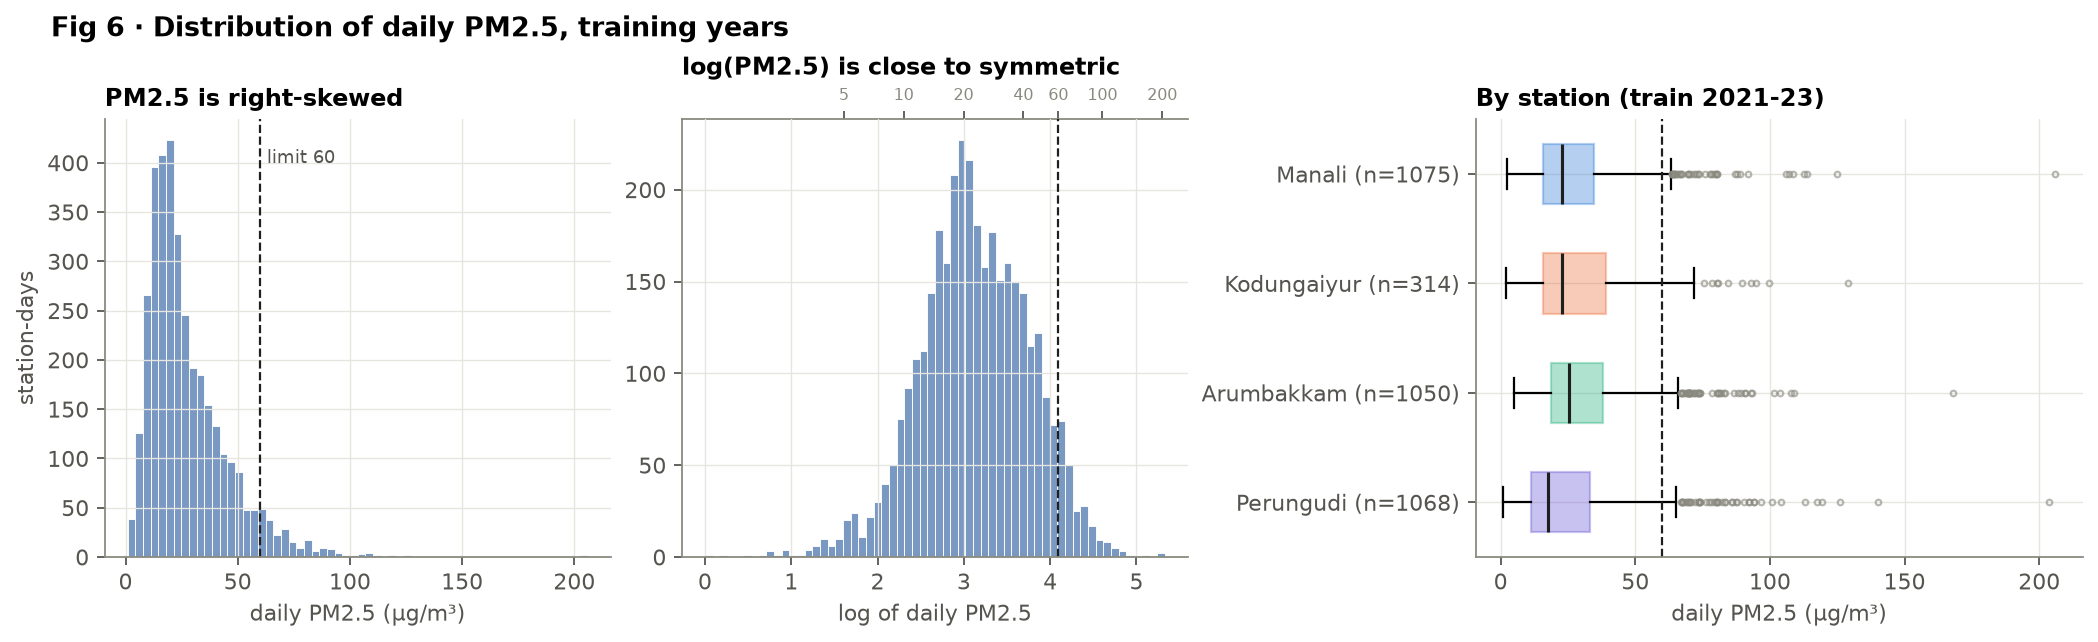

In [5]:
show(eda.fig_distribution(tr))

**What this shows**
* PM2.5 is **right-skewed** at every station (skew 1.6-2.5; mean > median by 3-7 µg/m³). The
  exceedance days we care about sit in the long tail. On a log scale the distribution is
  close to symmetric, so **log(PM2.5)** is the natural scale for lag features and for
  t-tests on PM2.5.
* The 60 µg/m³ line sits around the **95th percentile** at every station, so exceedance is a
  rare event, about 1 day in 16.
* Station medians differ (Perungudi lowest, Arumbakkam highest), so the model should know
  which station a row is from.

In [6]:
lab = tr.dropna(subset=["y"])
imb = lab.groupby("station")["y"].agg(labelled_days="size", exceed_days="sum", rate="mean")
imb.loc["all"] = [len(lab), lab.y.sum(), lab.y.mean()]
imb

,labelled_days,exceed_days,rate
station,,,
Arumbakkam,1050,72,0.06857
Kodungaiyur,313,23,0.07348
Manali,1075,56,0.05209
Perungudi,1068,64,0.05993
all,3506,215,0.06132


**Imbalance.** Only **215 of 3,506** labelled training rows are positive (6.1%). A model that
always says "no" is 94% accurate and useless, which is why the problem statement uses
recall, precision and PR-AUC and not accuracy. With so few positives, simple models with
few features are safer than complex ones.

## 2 · Missing data

In [7]:
miss = tr.assign(year=tr.target_date.dt.year).groupby(["station", "year"])["y"].apply(lambda s: s.isna().mean())
miss.unstack().reindex(eda.STATION_ORDER).style.format("{:.0%}")

year,2021,2022,2023
station,,,
Manali,1%,1%,3%
Kodungaiyur,14%,100%,100%
Arumbakkam,6%,3%,3%
Perungudi,3%,2%,2%


**Why the target is missing.** It is **not random** for Kodungaiyur: 2022-23 is missing because
we removed the drifting PM2.5 sensor (notebook 01). Elsewhere, gaps are scattered outages
(2-5%). Two consequences:
* We **do not impute the target.** A filled-in PM2.5 value is a guess, and training on guesses
  teaches the model our own interpolation. Rows without a label are dropped from training and scoring.
* With only ~300 Kodungaiyur days, a separate model per station would be very weak.
  → **One pooled model for all four stations, with station as a feature.** The same
  reasoning applies to the validation year, where Manali's 6-month drift period is also excluded.

## 3 · Seasonality
**Hypothesis H1:** the chance that tomorrow exceeds the limit depends on the season.

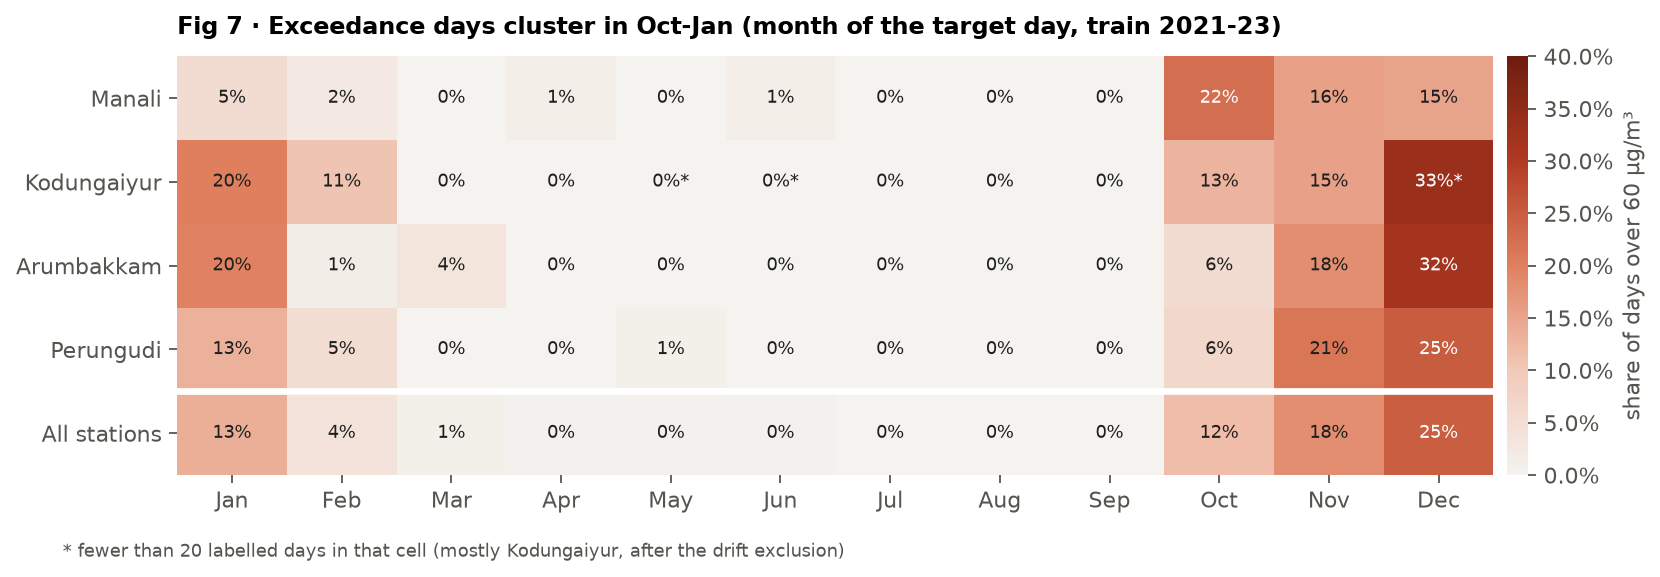

In [8]:
show(eda.fig_seasonality(tr))

In [9]:
lab = tr.dropna(subset=["y"])
h1 = eda.two_proportions(lab.y, lab.target_date.dt.month.isin(eda.WINTER), ("Oct-Feb", "Mar-Sep"))
table(h1)

,value
n Oct-Feb,1448
rate Oct-Feb,0.1443
n Mar-Sep,2058
rate Mar-Sep,0.0029
difference,0.1414
95% CI,"(0.1232, 0.1597)"
chi2,292.9
dof,1
p_value,1.18e-65


**Result.** In **Oct-Feb 14.4%** of days exceed the limit. In **Mar-Sep it is 0.3%** (6 days in
three years). The difference is 14 percentage points (95% CI 12-16 points). The chi-square test
of independence rejects "season does not matter" overwhelmingly.

**Why (domain knowledge):** in Chennai's winter and north-east monsoon season the air is cooler
and calmer, the mixing layer is shallower, and winds turn northerly over land. Pollution
builds up instead of being blown out to sea. In the south-west monsoon months the steady
sea breeze keeps the air clean.

→ **Feature:** month (encoded as a cycle, so that December sits next to January).
→ **Modelling note:** almost every positive is in Oct-Feb. A model can look good by
learning *only* the season, so the error analysis must check performance **within** Oct-Feb.

## 4 · Persistence: today predicts tomorrow
**Hypothesis H2:** a day over the limit makes the next day more likely to be over the limit.

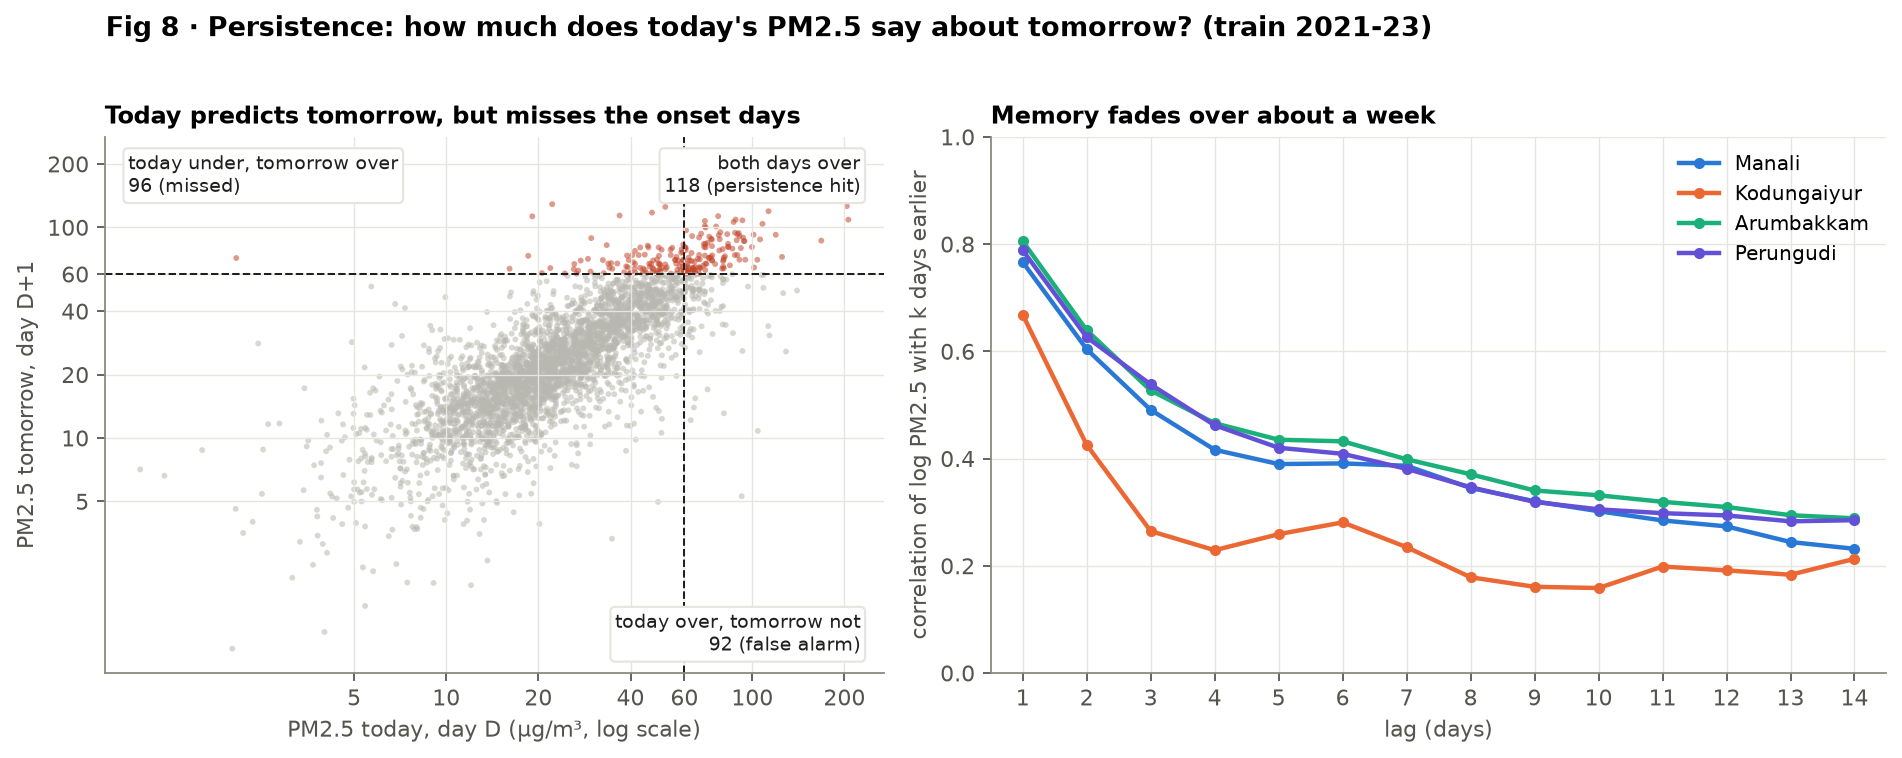

,Manali,Kodungaiyur,Arumbakkam,Perungudi
lag (days),,,,
1,0.77,0.67,0.81,0.79
2,0.6,0.43,0.64,0.63
3,0.49,0.26,0.53,0.54
4,0.42,0.23,0.47,0.46
5,0.39,0.26,0.44,0.42
6,0.39,0.28,0.43,0.41
7,0.39,0.23,0.4,0.38


In [10]:
acf = eda.autocorr(tr)
show(eda.fig_persistence(tr, acf))
acf.head(7).round(2)

In [11]:
lab2 = tr.dropna(subset=["y", "exceed_today"])
h2 = eda.two_proportions(lab2.y, lab2.exceed_today == 1, ("over today", "not over today"))
table(h2)

,value
n over today,210
rate over today,0.5619
n not over today,3256
rate not over today,0.0295
difference,0.5324
95% CI,"(0.4651, 0.5998)"
chi2,956.2
dof,1
p_value,6.06e-210


**Result.** If today is over 60, tomorrow is over 60 **56%** of the time. If today is not, only
**3%**. That is a 53-point difference (95% CI 47-60). Log PM2.5 has a lag-1 correlation of
0.67-0.81, and the correlation fades to about 0.4 by a week.

**What this means**
* The **persistence baseline** ("tomorrow = today") is strong: in training it catches 118 of the 215
  exceedance days and raises 92 false alarms. Beating it is the real test of any model.
* Its weakness is visible in the top-left of the scatter: **96 days where tomorrow is bad but
  today was not** (onset days). Those are exactly what weather and trend features need to catch.
→ **Features:** today's log PM2.5, the change from yesterday, rolling 3- and 7-day means.

### Robustness: how much does autocorrelation inflate the p-values?
With lag-1 correlation r ≈ 0.76, a rough rule says n rows behave like
n·(1−r)/(1+r) independent ones, here about **14% of n**. Shrinking the test statistics by that
factor:

In [12]:
r1 = acf.loc[1].mean()
ratio = eda.n_effective(1, r1)
print(f"mean lag-1 autocorrelation = {r1:.2f}  ->  effective share of rows = {ratio:.2f}")
pd.DataFrame({"naive p": [h1["p_value"], h2["p_value"]],
              "p with n_eff": [eda.p_with_n_effective(h1, ratio), eda.p_with_n_effective(h2, ratio)]},
             index=["H1 season", "H2 persistence"]).map(lambda v: f"{v:.1e}")

mean lag-1 autocorrelation = 0.76  ->  effective share of rows = 0.14


,naive p,p with n_eff
H1 season,1.2e-65,2.0e-10
H2 persistence,6.1e-210,1.4e-30


Even after the correction both p-values stay far below 0.05. The conclusions do not depend
on the independence assumption. The naive p-values are still too optimistic, and we say so.

## 5 · Stations move together

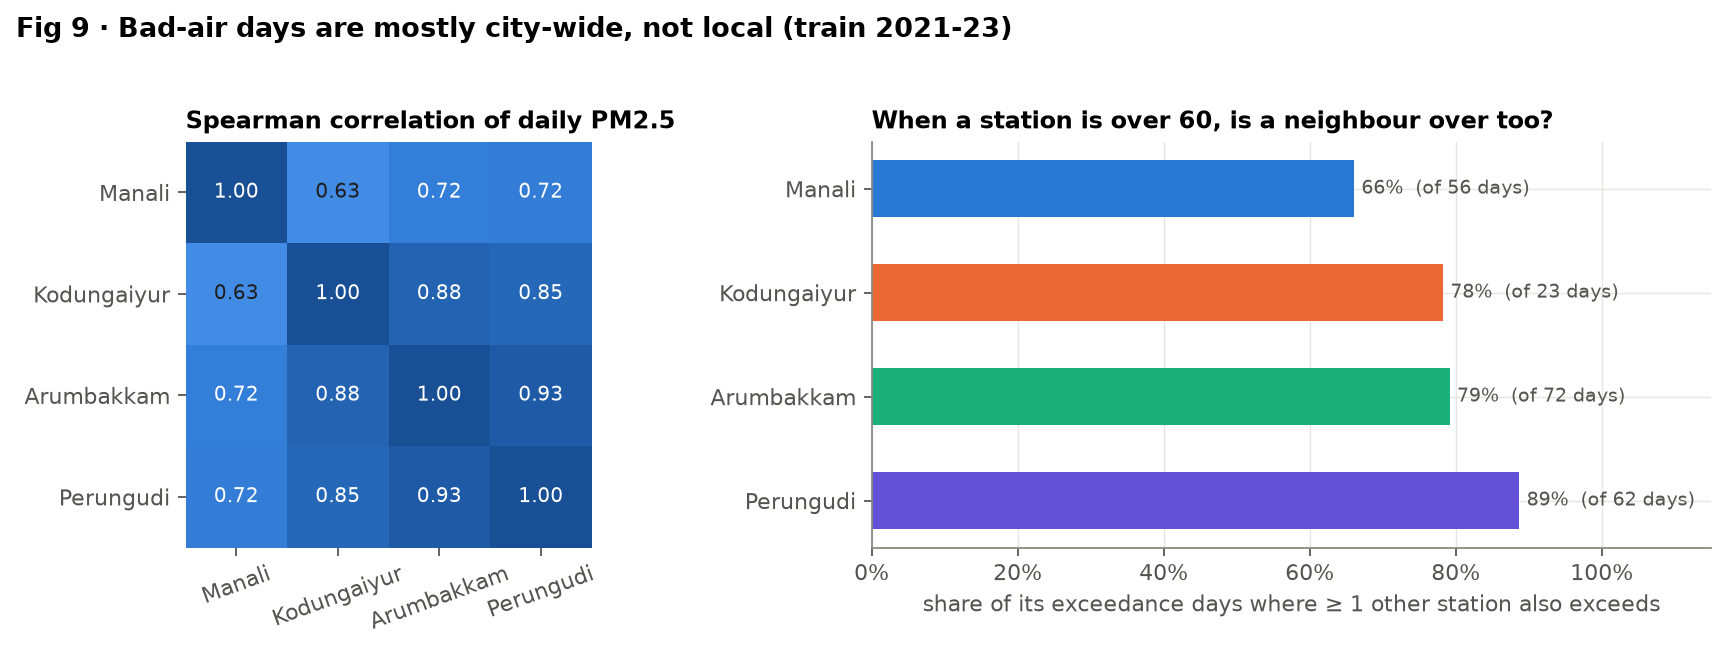

In [13]:
show(eda.fig_station_sync(tr))

**What this shows.** Daily PM2.5 at the four stations is strongly rank-correlated (0.63-0.93;
Manali, the industrial site, is the most independent). When one station exceeds the limit, at
least one neighbour usually exceeds it on the same day. Bad-air days are mostly a
**city-wide weather event**, not a local one. This also supports the peer-drift check used in
cleaning, which assumed exactly this.

→ **Feature:** today's city-wide mean PM2.5 (mean of the other stations that report).
It also gives Kodungaiyur and Manali a signal on days their own sensor is missing.

## 6 · Today's weather vs tomorrow's PM2.5
**Hypothesis H3:** day-D weather carries information about day D+1's PM2.5. Only day-D weather
is used, because day-D+1 weather is not known when the forecast is issued.

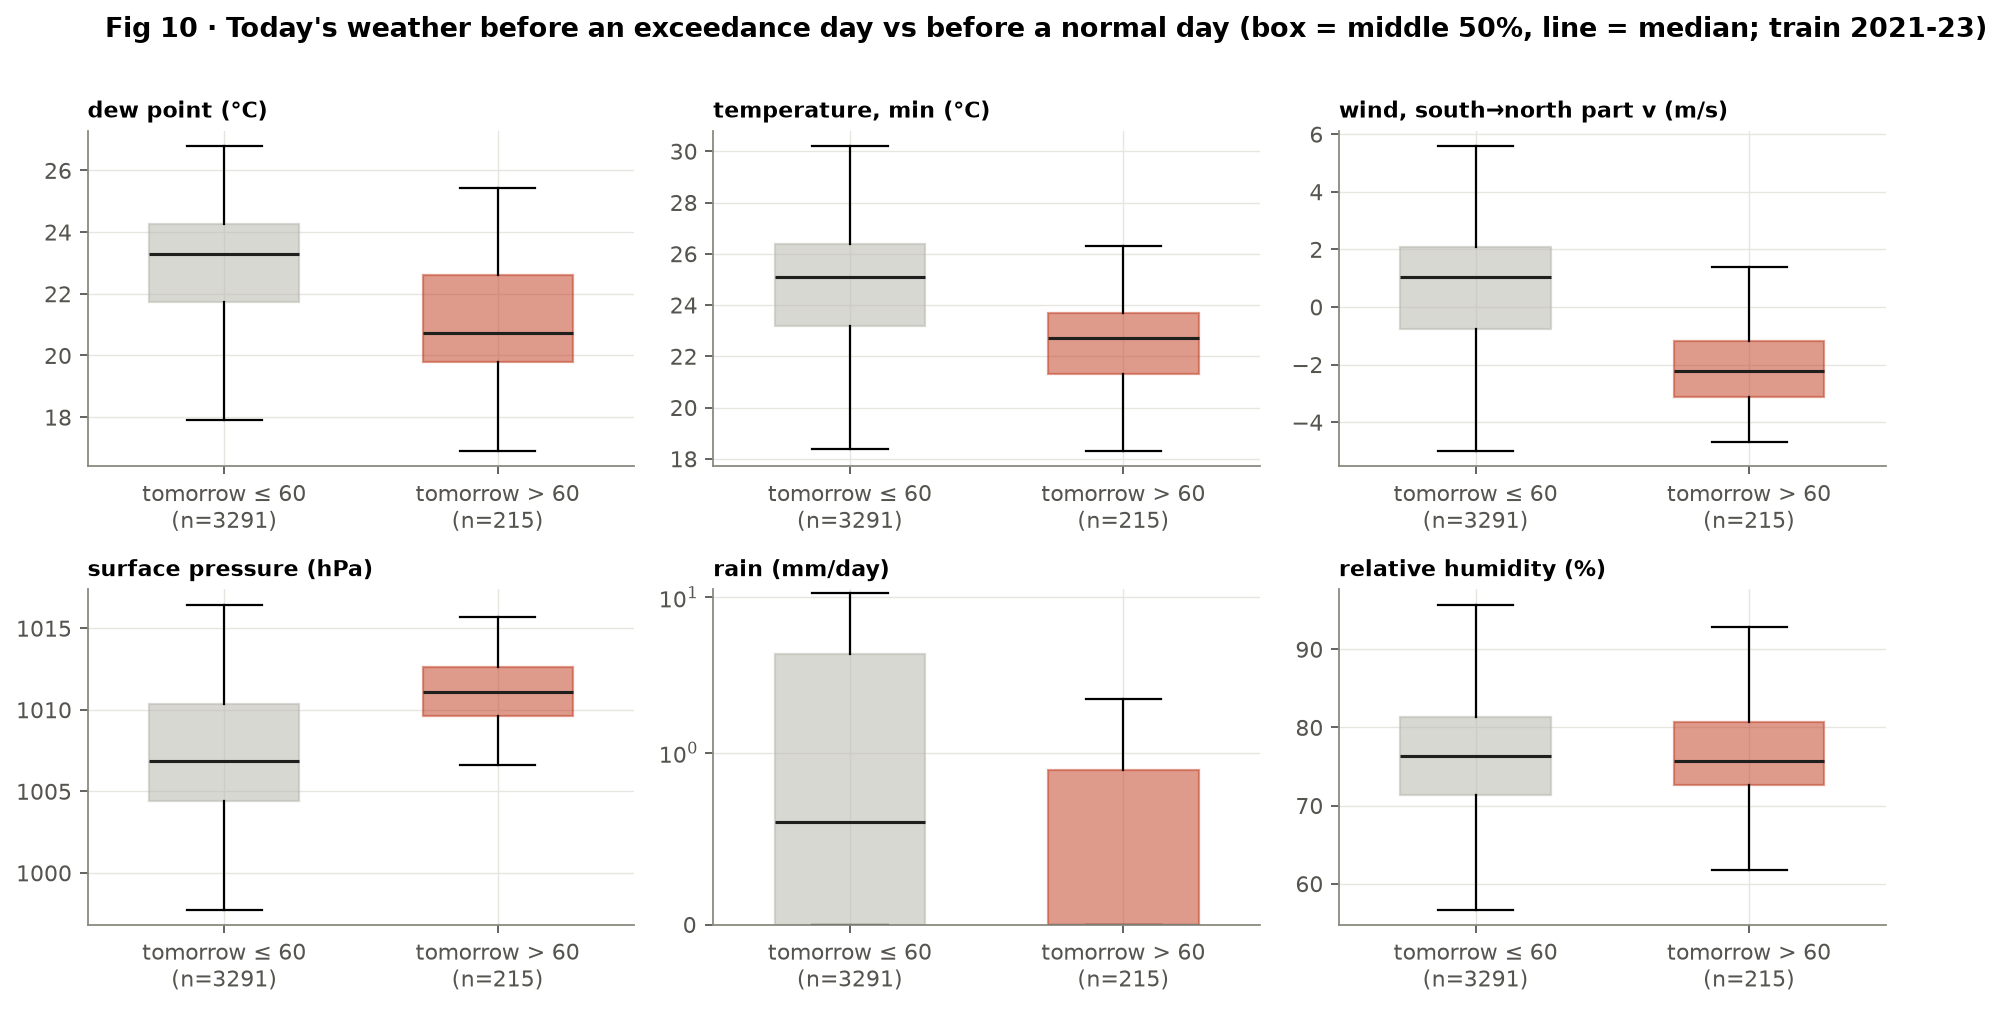

In [14]:
show(eda.fig_weather_by_class(tr, ["w_dewpoint_mean", "w_temp_min", "w_wind_v",
                                   "w_pressure_hpa", "w_rain_mm", "w_rh_mean"]))

Before an exceedance day, today is typically **cooler and drier** (lower dew point), with
**higher pressure**, a **northerly wind** (negative v), and **little rain**.

**Rain test (Welch's t-test on log PM2.5 tomorrow).** A "rain day" uses the India Meteorological
Department definition, ≥ 2.5 mm. Welch's version does not assume equal variances.

In [15]:
lab = tr.dropna(subset=["y"]).copy()
lab["log_next"] = np.log(lab.pm25_next)
rain = lab.w_rain_mm >= 2.5
h3 = eda.welch(lab.log_next[rain], lab.log_next[~rain], ("rain day", "dry day"))
h3_naive_p, h3_eff_p = h3["p_value"], eda.p_with_n_effective(h3, ratio)
table(h3)

,value
n rain day,1107
mean rain day,2.915
n dry day,2399
mean dry day,3.216
difference,-0.302
95% CI,"(-0.345, -0.258)"
t,-13.55
df,2264
p_value,2.92e-40


Tomorrow's log PM2.5 is 0.30 lower after a rain day (95% CI 0.26-0.35), i.e. about
**26% lower PM2.5** (e^−0.30 ≈ 0.74). That is rain washing particles out of the air.

In [16]:
print(f"p-value naive: {h3_naive_p:.1e}   with effective n: {h3_eff_p:.1e}")

p-value naive: 2.9e-40   with effective n: 8.0e-07


## 7 · Trap check: is the weather effect real, or just the season in disguise?
Season drives both weather *and* pollution: winter is cooler *and* dirtier. A weather variable
can therefore correlate with PM2.5 only because it marks the season. This is the confounding
behind **Simpson's paradox** (slide 26). We test it by recomputing each correlation **inside**
a season.

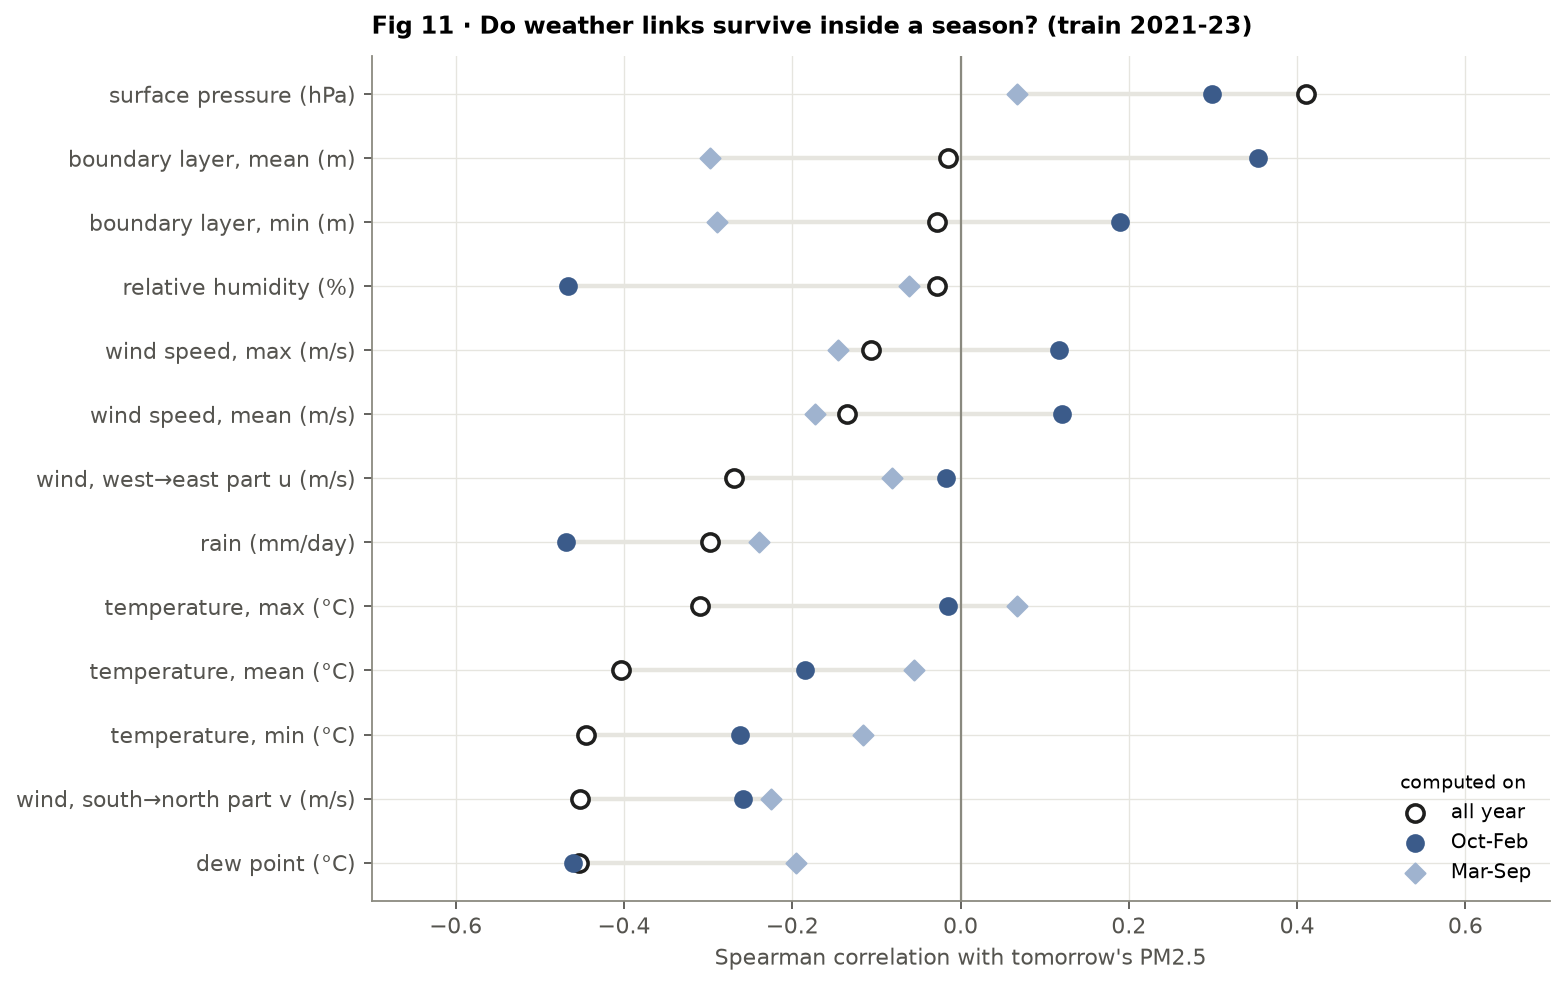

,all year,Oct-Feb,Mar-Sep
feature,,,
w_dewpoint_mean,-0.453,-0.46,-0.195
w_wind_v,-0.452,-0.259,-0.225
w_temp_min,-0.445,-0.262,-0.116
w_temp_mean,-0.403,-0.185,-0.055
w_temp_max,-0.31,-0.015,0.067
w_rain_mm,-0.298,-0.469,-0.239
w_wind_u,-0.269,-0.017,-0.082
w_wind_mean,-0.135,0.121,-0.173
w_wind_max,-0.107,0.117,-0.146


In [17]:
wcols = [c for c in tr.columns if c.startswith("w_")]
sp = eda.spearman_table(tr, wcols, seasons={"Oct-Feb": eda.WINTER, "Mar-Sep": [3, 4, 5, 6, 7, 8, 9]})
show(eda.fig_simpson(sp))
sp[["all year", "Oct-Feb", "Mar-Sep"]].sort_values("all year")

**Three different stories come out of the same table:**

| Pattern | Variables | Meaning |
|---|---|---|
| **Holds inside the season** | dew point (−0.45 → −0.46), rain (−0.30 → −0.47), pressure (+0.41 → +0.30) | Real day-to-day signal. Keep. |
| **Mostly the season** | temperature max (−0.31 → −0.02), wind u (−0.27 → −0.02), temperature mean (−0.40 → −0.19) | Mainly a calendar proxy. Month already carries it. |
| **Hidden by pooling** | humidity (−0.03 all year → **−0.47** in winter); boundary-layer height (−0.02 all year, but **+0.35** in winter and **−0.30** in Mar-Sep) | The two seasons pull in opposite directions and cancel. A whole-year correlation would have thrown them away. This is Simpson's paradox. |

Correlation is not causation, and the boundary-layer result shows why. Physics says a *deeper*
mixing layer should *dilute* pollution, yet in winter it goes with *more* PM2.5. Rain does not
explain it (the link is still +0.36 on dry winter days). Where the air comes from does:

In [18]:
win = tr[tr.date.dt.month.isin(eda.WINTER)]
from scipy import stats
print("Winter, Spearman of boundary-layer height with:")
for c in ["w_wind_v", "w_dewpoint_mean"]:
    print(f"   {c:16s} {stats.spearmanr(win.w_blh_mean, win[c], nan_policy='omit')[0]:+.2f}")
print(f"\nBLH vs tomorrow's PM2.5, winter:                    "
      f"{stats.spearmanr(win.w_blh_mean, win.pm25_next, nan_policy='omit')[0]:+.2f}")
print(f"... after removing what dew point explains:         "
      f"{eda.partial_spearman(win, 'w_blh_mean', 'pm25_next', 'w_dewpoint_mean'):+.2f}")

Winter, Spearman of boundary-layer height with:
   w_wind_v         -0.66
   w_dewpoint_mean  -0.48

BLH vs tomorrow's PM2.5, winter:                    +0.35
... after removing what dew point explains:         +0.16


In winter a deep boundary layer comes with **dry, northerly air from the land**, which carries
the city's and the industrial north's pollution. Moist sea air has a shallow layer but is clean.
Once dew point (a marker of the air mass) is accounted for, most of the link disappears.
Boundary-layer height is a stand-in for the air mass, not a cause.

→ **Features:** dew point, rain (today and the last 3 days), pressure, wind components, and
humidity. Month interactions are worth trying, since several effects are season-specific.
→ **Drop boundary-layer height:** it adds little beyond dew point and wind, and Open-Meteo has no
values for Jan-Jun 2024 (half the validation year).

## 8 · Calendar effects: festivals and weekdays

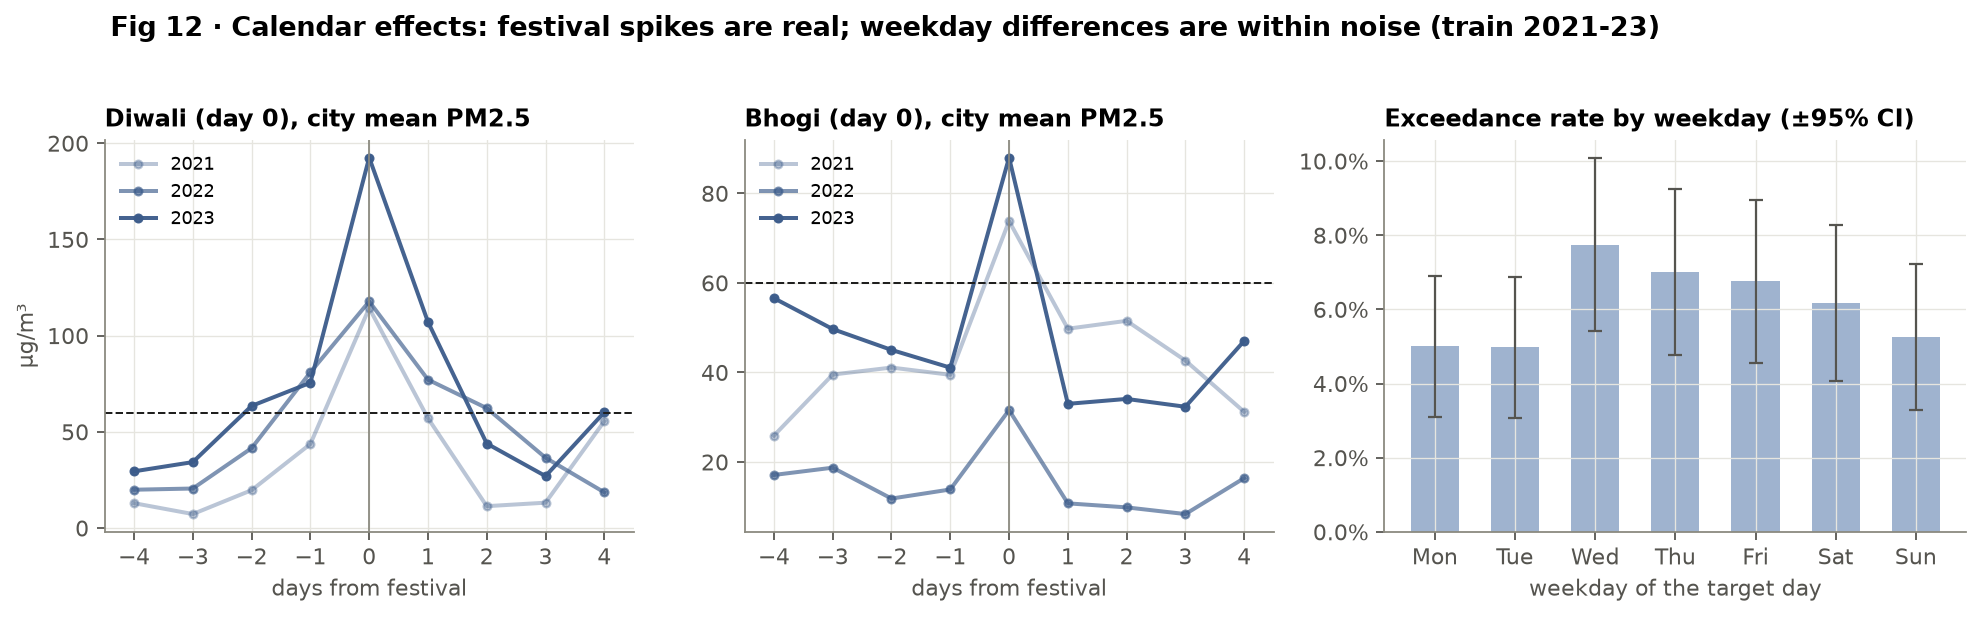

,days,exceed_rate
festival day,19,0.7895
other day,3487,0.05736


In [19]:
show(eda.fig_calendar(df[df.split == "train"], tr))
lab = tr.dropna(subset=["y"])
fest = festival_flags(lab.target_date)
lab.groupby(np.where(fest != "", "festival day", "other day"))["y"].agg(days="size", exceed_rate="mean")

In [20]:
h4 = eda.chi2_independence(lab.y, lab.target_date.dt.day_of_week)
display(h4["table"].set_axis(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).T)
table(h4)

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
y,,,,,,,
0,475,477,465,465,469,472,468
1,25,25,39,35,34,31,26


,value
chi2,6.18
dof,6
p_value,4.04e-01
min_expected,30.3


**Festivals.** On Diwali and Bhogi, **79%** of station-days exceed the limit, against 6% on
other days (only 19 festival station-days in training, so the exact rate is uncertain). Bhogi
spikes for one day, and Diwali's spike lasts into the next day. These dates are fixed by the
calendar and known in advance, so a festival flag on day D+1 is **not leakage**.
→ **Feature:** "tomorrow is a festival day" (Diwali, Bhogi), plus "today was a festival" for the
spill-over.

**Weekdays (H4).** Mid-week rates are slightly higher (traffic?), but the chi-square test gives
**p = 0.40**: we cannot reject "weekday does not matter". This is a useful *null* result.
→ **Do not add a weekday feature.** Adding things that test as noise invites overfitting with
only 215 positives.

**Multiple testing.** We ran four planned tests (H1-H4) plus the correlation table. At a 5% level
about one in twenty true-null comparisons would look "significant" by luck. H1-H3 have p-values
many orders of magnitude below any Bonferroni-corrected threshold (0.05/4), so this does not
change any conclusion. The small correlations in §7 (|r| < 0.1) should not be trusted on their own.

## 9 · Data drift: the base rate is not stable
*This section uses all years, but only to count bad days. Nothing here is used to choose features.*

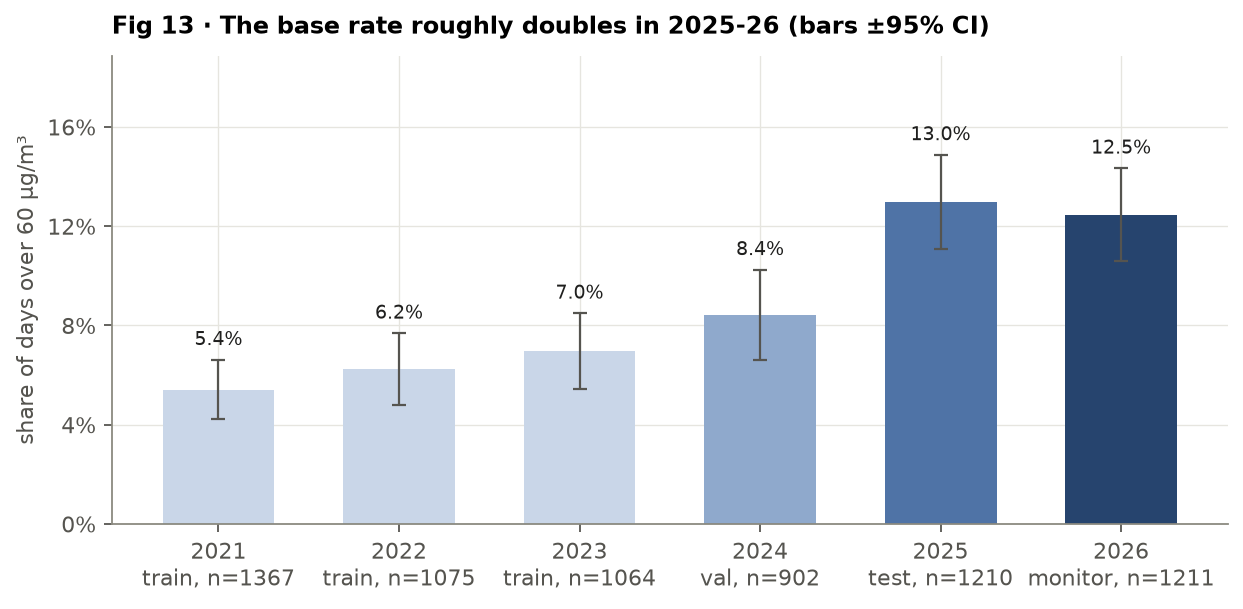

In [21]:
show(eda.fig_base_rate(df))

The share of exceedance days roughly **doubles from training (6.1%) to test and monitoring (~13%)**,
and the 95% intervals do not overlap. Possible reasons, none of which we can prove from this data:
more burning or traffic, a change in instruments after Kodungaiyur's 2025 maintenance (it is
back in the data from Mar 2025), or weather years that favoured stagnant air.

**What it means for the model.** The model will learn "bad days are rare" from training. That
affects the probability scale (a predicted 10% may really be 20%) more than the ranking of days.
So:
* **PR-AUC and the alert threshold must be read in the light of the base rate.** A no-skill model
  has PR-AUC equal to the positive rate: 0.06 in training, 0.13 in test. A test PR-AUC is
  compared against 0.13, not 0.06.
* Calibration will be checked on the test year in stage 7, and monitoring in 2026 (stage 9) will
  track whether recall holds.

## 10 · Summary: hypotheses → evidence → features

| # | Hypothesis | Evidence (train 2021-23) | Decision for stage 5/6 |
|---|---|---|---|
| H1 | Season matters | 14.4% vs 0.3% exceed; p ≪ 0.001 even with n_eff | Month as a cycle (sin/cos); check errors within Oct-Feb |
| H2 | Today predicts tomorrow | 56% vs 3%; lag-1 r ≈ 0.76 | log PM2.5 today, 1-day change, 3/7-day means; persistence baseline |
| — | Stations move together | r = 0.63-0.93 | City-wide mean PM2.5 today; one pooled model with station indicator |
| H3 | Today's weather helps | rain day → 26% lower PM2.5 tomorrow; dew point, pressure hold within season | dew point, RH, rain (today + 3-day), pressure, wind u/v; drop BLH |
| — | Festivals spike | 79% vs 6% exceed | "festival tomorrow / today" flags |
| H4 | Weekday matters | p = 0.40 | No weekday feature |
| — | Base rate drifts | 6% → 13% | Compare PR-AUC to the base rate; check calibration in stage 7 |

**Leakage checklist carried forward:** no D+1 measurements in features (festival dates are
calendar facts, not measurements); target never imputed; all scalers/imputers fitted on 2021-23.

**Next:** `03_features.ipynb` (stage 5): build these features in `src/features.py`, and set up
the time-series cross-validation inside the training years.